Recall analyses connect response data to numerical summaries and figures.
JAXCMR exposes several interfaces for this work. The appropriate entry point
depends on whether a function receives recall arrays, a dataset, or model
simulations to compare with observations.

## The analysis interfaces

| Interface | Example | Input → output |
|---|---|---|
| Array calculation | `fixed_pres_spc()` | Recall array and list length → values by study position. |
| Dataset analysis | `spc()` | A selected dataset → values by study position, accounting for repeated study items. |
| Participant aggregation | `apply_by_subject()` | Dataset, mask and dataset-analysis function → one result per selected participant. |
| Plotting | `plot_spc()` | Dataset(s) and mask(s) → a Matplotlib `Axes`, with participant summaries and intervals. |
| Objective callback | `RecallAnalysisFn` | Selected observed or simulated recalls and metadata → a comparable numerical summary. |

Functions in `jaxcmr.analyses` have task-specific arguments. Read their
signatures when choosing an analysis; array calculations, dataset functions
and objective callbacks have different responsibilities.

## Adding a summary to a model objective {#recallanalysisfn}

`RecallAnalysisFn` is an **extension point** for supplying your own summary
calculation to the behavioral-summary loss in `jaxcmr.loss.mse`. A normal
Python function with this signature can be passed directly. It does not
need a base class or registration step.

Declaration from [`jaxcmr.typing`](https://github.com/githubpsyche/jaxcmr/blob/main/jaxcmr/typing.py):

```python
class RecallAnalysisFn(Protocol):
    def __call__(
        self,
        recalls: Integer[Array, " trials simulations recall_positions"],
        *,
        list_length: int,
        dataset: Mapping[str, Array],
        trial_indices: Integer[Array, " trials"],
    ) -> Array: ...
```

The loss calls the function on observations and model simulations:

- `recalls` already contains the selected trials. Its axes are trial,
  simulation and response position. Observations have one simulation per
  trial; predictions can have several, and their response width may differ.
- `dataset` remains the full dataset. Use `dataset[field][trial_indices]`
  to align accompanying trial or study information with `recalls`.
- `list_length` supplies the model's study-list width. Return the same
  fixed output shape for observed and simulated data, aggregating the
  simulation axis according to the intended statistic.

The callback must support JAX tracing: use array operations with fixed
output shapes rather than data-dependent Python branching. It owns the
interpretation of recall codes, participant weighting and aggregation.
This loss does not translate observed position codes into model item codes
on the callback's behalf. Nonfinite observed bins can mark unavailable
targets; predictions must be finite wherever a target is available.

## Selecting and summarizing trials

`generate_trial_mask()` returns a one-dimensional Boolean mask; it does not
filter the dictionary itself. A dataset-based analysis receives the selected
rows of every field. `apply_by_subject()` performs that selection separately
for each participant and passes each selected dictionary to its function.

In [1]:
#| code-summary: "Select mixed lists and compare the analysis input/output shapes"

import jax.numpy as jnp
from jaxcmr.helpers import load_data, generate_trial_mask, apply_by_subject
from jaxcmr.analyses.spc import fixed_pres_spc, spc, plot_spc

data = load_data("data/Dupertuys2026.h5")
mixed = generate_trial_mask(data, "data['list_type'] == 1")
selected = {name: values[mixed] for name, values in data.items()}
pooled = spc(selected)
per_subject = jnp.stack(apply_by_subject(data, mixed, spc))
print("Selected trials:", int(mixed.sum()))
print("Pooled summary shape:", pooled.shape)
print("Participant summary shape:", per_subject.shape)

Selected trials: 246
Pooled summary shape: (12,)
Participant summary shape: (123, 12)


These 246 mixed lists are complete twelve-item lists without repeated study
items. Their within-list item codes match study positions. Consequently the
simple array calculation below can score both dataset recalls and model
item codes in this example.

`spc(selected)` pools trials. `apply_by_subject()` returns a list of results
in ascending participant-ID order, omitting participants with no selected
trials. It returns no ID column; retain the corresponding selected IDs when
needed. Averaging these results weights participants equally. With unequal
numbers of lists, that differs from pooling all trials.

`plot_spc()` performs participant aggregation and creates its own axes when
none are supplied. It returns those axes for further customization.

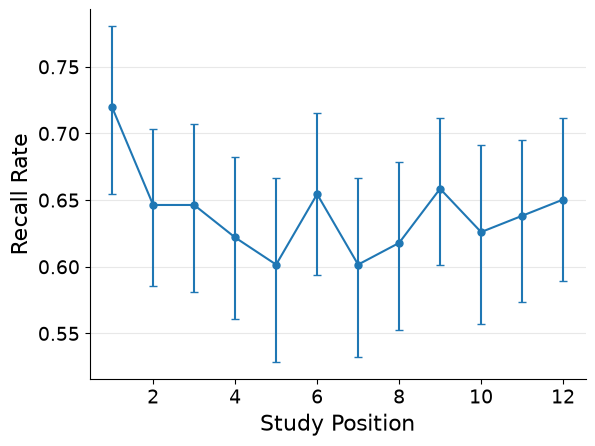

In [2]:
#| code-summary: "Use JAXCMR to plot participant-aggregated recall"

plot_spc(data, mixed, labels=["Mixed lists"]);

## Connecting a compatible callback

This adapter reuses `fixed_pres_spc()` and pools trials and replications into
one SPC. Its unused keyword arguments remain in the signature so the loss
can supply the same interface to any compatible callback. A summary using
conditions or participant IDs would use those metadata arguments.

In [3]:
#| code-summary: "Adapt the existing SPC calculation to RecallAnalysisFn"

from jaxcmr.loss.mse import make_factory as make_summary_loss

def spc_summary(recalls, *, list_length, dataset, trial_indices):
    return fixed_pres_spc(
        recalls.reshape(-1, recalls.shape[-1]), list_length
    )

SpcLoss = make_summary_loss({"spc": spc_summary}, simulation_count=2)
trial_indices = jnp.flatnonzero(mixed)
observed_summary = spc_summary(
    data["recalls"][trial_indices, None, :], list_length=12,
    dataset=data, trial_indices=trial_indices,
)
observed_summary

Array([0.7195122 , 0.64634144, 0.64634144, 0.6219512 , 0.60162604,
       0.6544715 , 0.60162604, 0.6178862 , 0.6585366 , 0.62601626,
       0.63821137, 0.6504065 ], dtype=float32)

`make_factory()` binds the named callback and simulation settings into a
loss class. Supply that class through a fitter's `loss_fn_cls` argument.
The small simulation count here illustrates the connection; it is not a
recommendation for estimating parameters.

In [4]:
#| code-summary: "Supply the configured summary loss to a fitter without running a fit"

from pathlib import Path
import json
import jax.numpy as jnp
from jaxcmr.helpers import load_data, generate_trial_mask
from jaxcmr.components import context, linear_memory
from jaxcmr.components.termination import NoStopTermination
from jaxcmr.models.cmr import make_factory

data = load_data("data/Dupertuys2026.h5")
record = json.loads(Path("data/fits/Dupertuys2026_CMR_demo.json").read_text())
parameters = {name: values[0] for name, values in record["fits"].items()
              if name != "subject"}
for name in ("allow_repeated_recalls", "learn_after_context_update"):
    parameters[name] = bool(parameters[name])

CMRFactory = make_factory(
    mfc_create_fn=linear_memory.init_mfc,
    mcf_create_fn=linear_memory.init_mcf,
    context_create_fn=context.init,
    termination_policy_create_fn=NoStopTermination,
)

from jaxcmr.fitting import ScipyDE

fitter = ScipyDE(
    dataset=data, features=None, base_params=record["fixed"],
    model_factory_cls=CMRFactory, loss_fn_cls=SpcLoss,
    hyperparams={"bounds": record["free"]},
)
print("Configured summaries:", tuple(fitter.loss_fn.analysis_fns))

Configured summaries: ('spc',)


A compatible callback is reusable through the existing loss and fitter.
More complex datasets may require an adapter that translates codes,
handles repeated presentations or preserves participant weighting. The
`RecallAnalysisFn` signature provides the necessary inputs; it does not
choose those scientific conventions.

See [Loss Functions](losses.ipynb) for the objective interface and
[Fitting Procedures](fitting.ipynb) for fitting configuration. The
[SPC template](../templates/spc.ipynb) covers the complete behavioral
procedure and interpretation of its curve.